# Prediksi Harga Rumah Depok
**Early Bird – Bengkel Koding Data Science (Ganjil 2026/2027)**
Nama: Ferdian Nur Fariza | NIM: A11.2023.15074

Alur: **EDA → Direct Modeling → Preprocessing & Modeling → Feature Selection → Hyperparameter Tuning → Simpan Model**
Target: `Harga` (regresi). Satuan harga di seluruh notebook: **Juta Rupiah**.
Stack: **Polars** untuk data wrangling, **scikit-learn / XGBoost** untuk modeling, **matplotlib** untuk visualisasi.

## 0. Setup

In [1]:
import os, re, json, time, warnings
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import joblib
from functools import partial
from scipy.stats import spearmanr, skew

from sklearn.base import clone
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, mutual_info_regression
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score, mean_squared_error
from xgboost import XGBRegressor

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
pl.Config.set_tbl_rows(40); pl.Config.set_tbl_cols(-1); pl.Config.set_fmt_str_lengths(90)
SEED = 42

def bulat(df, n=2):
    return df.with_columns(pl.col(pl.Float64).round(n))

def spearman(a, b):                      # korelasi Spearman, abaikan pasangan yang kosong
    ok = ~(np.isnan(a) | np.isnan(b))
    return spearmanr(a[ok], b[ok])[0]

def n_dup(df, subset=None):              # jumlah baris duplikat (selain kemunculan pertama)
    sub = df.select(subset) if subset else df
    return sub.height - sub.unique().height

In [2]:
DATA_PATH = 'Raw-Final-Rumah.csv'
if not os.path.exists(DATA_PATH):   # untuk Google Colab
    !gdown 1T_wjbyeNGFib77hi4a61ktfTmJLLk0UQ -O {DATA_PATH}
df_raw = pl.read_csv(DATA_PATH, infer_schema_length=None)
df_raw.shape

(40200, 8)

## 1. EDA

### 1.1 Gambaran umum

In [3]:
display(df_raw.head(8))
df_raw.glimpse()
print('\nMissing value per kolom:'); display(df_raw.null_count())

Harga,Kamar Tidur,Kamar Mandi,Garasi,Luas Tanah,Luas Bangunan,Kecamatan,Page
str,str,str,str,str,str,str,i64
"""2,5 Miliar""","""4""","""3""","""10""","""LT : 438 m²""","""LB : 110 m²""","""Tapos""",129
"""385 Juta""","""3""","""2""","""1""","""LT : 50 m²""","""LB : 60 m²""","""Pancoran Mas""",129
"""385 Juta""","""3""","""2""","""1""","""LT : 50 m²""","""LB : 60 m²""","""Cipayung""",129
"""385 Juta""","""3""","""2""","""1""","""LT : 50 m²""","""LB : 60 m²""","""Rangkapanjaya""",129
"""385 Juta""","""3""","""2""","""1""","""LT : 50 m²""","""LB : 60 m²""","""Pancoran Mas""",129
"""385 Juta""","""3""","""2""","""1""","""LT : 50 m²""","""LB : 60 m²""","""Cipayung""",129
"""950 Juta""","""2""","""1""","""1""","""LT : 87 m²""","""LB : 50 m²""","""Sawangan""",129
"""525 Juta""","""2""","""1""","""LB:41 m²""",null,null,"""Cinere""",129


Rows: 40200
Columns: 8
$ Harga         <str> '2,5 Miliar', '385 Juta', '385 Juta', '385 Juta', '385 Juta', '385 Juta', '950 Juta', '525 Juta', '2,5 Miliar', '3,7 Miliar'
$ Kamar Tidur   <str> '4', '3', '3', '3', '3', '3', '2', '2', '3', '4'
$ Kamar Mandi   <str> '3', '2', '2', '2', '2', '2', '1', '1', '2', '3'
$ Garasi        <str> '10', '1', '1', '1', '1', '1', '1', 'LB:41 m²', 'LT:409 m²', 'LT:280 m²'
$ Luas Tanah    <str> 'LT : 438 m²', 'LT : 50 m²', 'LT : 50 m²', 'LT : 50 m²', 'LT : 50 m²', 'LT : 50 m²', 'LT : 87 m²', null, 'LB : 300 m²', 'LB : 240 m²'
$ Luas Bangunan <str> 'LB : 110 m²', 'LB : 60 m²', 'LB : 60 m²', 'LB : 60 m²', 'LB : 60 m²', 'LB : 60 m²', 'LB : 50 m²', null, null, null
$ Kecamatan     <str> 'Tapos', 'Pancoran Mas', 'Cipayung', 'Rangkapanjaya', 'Pancoran Mas', 'Cipayung', 'Sawangan', 'Cinere', 'Sukmajaya', 'Cinere'
$ Page          <i64> 129, 129, 129, 129, 129, 129, 129, 129, 129, 129


Missing value per kolom:


Harga,Kamar Tidur,Kamar Mandi,Garasi,Luas Tanah,Luas Bangunan,Kecamatan,Page
u32,u32,u32,u32,u32,u32,u32,u32
0,9,4403,5189,7699,15602,0,0


### 1.2 Pola isi kolom
Kolom fitur (`Kamar Tidur` s.d. `Luas Bangunan`) tampaknya tidak konsisten isinya. Cek dulu pola tiap baris:
`n` = angka biasa, `T` = `LT…`, `B` = `LB…`, `_` = kosong.

In [4]:
KOLOM_FITUR = ['Kamar Tidur', 'Kamar Mandi', 'Garasi', 'Luas Tanah', 'Luas Bangunan']

def simbol(c):
    return (pl.when(pl.col(c).is_null()).then(pl.lit('_'))
              .when(pl.col(c).str.starts_with('LT')).then(pl.lit('T'))
              .when(pl.col(c).str.starts_with('LB')).then(pl.lit('B'))
              .otherwise(pl.lit('n')))

pola = df_raw.select(pl.concat_str([simbol(c) for c in KOLOM_FITUR]).alias('pola'))['pola']
display(pola.value_counts(sort=True).head(8))
print('Baris dengan isi kolom tidak sesuai urutan normal (nnnTB):', (pola != 'nnnTB').sum())

pola,count
str,u32
"""nnnTB""",24598
"""nnTB_""",7900
"""T____""",4303
"""nTB__""",1379
"""nnB__""",1119
"""TB___""",548
"""nB___""",234
"""B____""",90


Baris dengan isi kolom tidak sesuai urutan normal (nnnTB): 15602


**Temuan:** atribut yang kosong tidak diberi placeholder, sehingga nilai sesudahnya **bergeser ke kiri** (mis. `LT : 438 m²` muncul di kolom `Kamar Tidur`).
Solusi: baca isi sel berdasarkan **tokennya** (`LT`/`LB`/angka), bukan berdasarkan nama kolom.
Angka biasa diurutkan sebagai Kamar Tidur → Kamar Mandi → Garasi.

### 1.3 Variasi format `Harga`

In [5]:
FAKTOR = {'Ribu': 1e-3, 'Juta': 1.0, 'Miliar': 1e3, 'Triliun': 1e6}   # ke Juta Rupiah

def parse_harga(df):
    g = pl.col('Harga').str.extract_groups(r'^\s*([\d.,]+)\s*(Ribu|Juta|Miliar|Triliun)\s*(.*)$')
    angka, satuan, ket = g.struct.field('1'), g.struct.field('2'), g.struct.field('3')
    return df.select(
        (angka.str.replace(',', '.', literal=True).cast(pl.Float64)
         * satuan.replace_strict(FAKTOR, default=None, return_dtype=pl.Float64)).alias('harga_juta'),
        satuan.fill_null('Tanpa angka').alias('satuan'),
        pl.when(ket.is_null() | (ket == '')).then(pl.lit('-')).otherwise(ket).alias('ket'),
    )

def realign(df):
    n = len(KOLOM_FITUR)
    d = df.select(
        *[pl.col(c).str.extract(r'(\d+)').cast(pl.Float64).alias(f'v{i}') for i, c in enumerate(KOLOM_FITUR)],
        *[pl.col(c).str.slice(0, 2).alias(f't{i}') for i, c in enumerate(KOLOM_FITUR)],
    )
    token = lambda tag: pl.coalesce([pl.when(pl.col(f't{i}') == tag).then(pl.col(f'v{i}')) for i in range(n)])
    angka = pl.concat_list([pl.when(~pl.col(f't{i}').is_in(['LT', 'LB'])).then(pl.col(f'v{i}')) for i in range(n)]).list.drop_nulls()
    return d.select(                                    # urutan angka biasa: KT, KM, Garasi
        angka.list.get(0, null_on_oob=True).alias('kamar_tidur'),
        angka.list.get(1, null_on_oob=True).alias('kamar_mandi'),
        angka.list.get(2, null_on_oob=True).alias('garasi'),
        token('LT').alias('luas_tanah'),
        token('LB').alias('luas_bangunan'),
    )

df_p = pl.concat([parse_harga(df_raw), realign(df_raw),
                  df_raw.select(pl.col('Kecamatan').alias('kecamatan'), pl.col('Page').alias('page'))], how='horizontal')
display(df_p.group_by(['satuan', 'ket']).len().sort(['satuan', 'ket']).rename({'len': 'jumlah'}))

satuan,ket,jumlah
str,str,u32
"""Juta""","""-""",13872
"""Juta""","""/ha""",1
"""Juta""","""/m²""",44
"""Juta""","""Total""",807
"""Miliar""","""-""",20262
"""Miliar""","""/m²""",11
"""Miliar""","""Total""",5083
"""Ribu""","""-""",12
"""Ribu""","""Total""",1


**Temuan:** selain `Juta`/`Miliar`, ada satuan `Ribu`, `Triliun`, keterangan `Total`, harga per `/m²` dan `/ha`, serta `Hubungi Agen` (tanpa angka).
Harga `Total` cukup di-strip, `/m²` dikalikan Luas Tanah, sisanya dibuang (tidak wajar / tidak ada harga).

**Validasi asumsi realign:** pada baris yang hanya punya 2 angka, angka kedua dianggap **Kamar Mandi** (garasi yang kosong).
Buktinya: korelasi dengan Luas Bangunan angka kedua itu mirip Kamar Mandi, bukan Garasi.

In [6]:
d = df_p.with_columns(pola.str.count_matches('n').alias('n_angka')).filter(pl.col('luas_bangunan').is_between(10, 3000))
tiga, dua = d.filter(pl.col('n_angka') == 3), d.filter(pl.col('n_angka') == 2)
sp = lambda df, kol: spearman(df[kol].to_numpy(), df['luas_bangunan'].to_numpy())
print('Spearman dengan Luas Bangunan')
print('  baris 3 angka  -> Kamar Mandi :', round(sp(tiga, 'kamar_mandi'), 3))
print('  baris 3 angka  -> Garasi       :', round(sp(tiga, 'garasi'), 3))
print('  baris 2 angka  -> angka ke-2   :', round(sp(dua, 'kamar_mandi'), 3))

Spearman dengan Luas Bangunan
  baris 3 angka  -> Kamar Mandi : 0.808
  baris 3 angka  -> Garasi       : 0.471
  baris 2 angka  -> angka ke-2   : 0.814


### 1.4 Duplikat dan nilai tidak wajar

In [7]:
KUNCI_DUP = ['harga_juta', 'kamar_tidur', 'kamar_mandi', 'garasi', 'luas_tanah', 'luas_bangunan']
print('Duplikat identik (semua kolom)                :', n_dup(df_raw))
print('Duplikat jika Page & Kecamatan diabaikan      :', n_dup(df_raw, ['Harga'] + KOLOM_FITUR))
print('Duplikat setelah parsing (harga/fitur numerik):', n_dup(df_p, KUNCI_DUP))
print('\nContoh listing yang sama muncul di beberapa Kecamatan:')
display(df_raw.filter((pl.col('Harga') == '385 Juta') & (pl.col('Luas Tanah') == 'LT : 50 m²'))
        .select('Harga', 'Luas Tanah', 'Kecamatan', 'Page').head(8))
print('\nRingkasan numerik (setelah realign, sebelum dibersihkan):')
display(df_p.select('harga_juta', 'kamar_tidur', 'kamar_mandi', 'garasi', 'luas_tanah', 'luas_bangunan')
        .describe(percentiles=[.01, .5, .99]))

Duplikat identik (semua kolom)                : 1525
Duplikat jika Page & Kecamatan diabaikan      : 12331
Duplikat setelah parsing (harga/fitur numerik): 12360

Contoh listing yang sama muncul di beberapa Kecamatan:


Harga,Luas Tanah,Kecamatan,Page
str,str,str,i64
"""385 Juta""","""LT : 50 m²""","""Pancoran Mas""",129
"""385 Juta""","""LT : 50 m²""","""Cipayung""",129
"""385 Juta""","""LT : 50 m²""","""Rangkapanjaya""",129
"""385 Juta""","""LT : 50 m²""","""Pancoran Mas""",129
"""385 Juta""","""LT : 50 m²""","""Cipayung""",129
"""385 Juta""","""LT : 50 m²""","""Rangkapanjaya""",130
"""385 Juta""","""LT : 50 m²""","""Pancoran Mas""",130
"""385 Juta""","""LT : 50 m²""","""Cipayung""",130



Ringkasan numerik (setelah realign, sebelum dibersihkan):


statistic,harga_juta,kamar_tidur,kamar_mandi,garasi,luas_tanah,luas_bangunan
str,f64,f64,f64,f64,f64,f64
"""count""",40159.0,35250.0,33636.0,24607.0,38736.0,35869.0
"""null_count""",41.0,4950.0,6564.0,15593.0,1464.0,4331.0
"""mean""",193981.957376,3.668652,2.749049,1.590442,37141.436003,25863.80097
"""std""",1.5192e7,4.719539,3.678546,1.396581,4.5196e6,4.3554e6
"""min""",0.0035,1.0,1.0,1.0,1.0,1.0
"""1%""",65.0,1.0,1.0,1.0,40.0,22.0
"""50%""",1500.0,3.0,2.0,1.0,115.0,100.0
"""99%""",64900.0,21.0,17.0,7.0,9000.0,1428.0
"""max""",1.9028e9,284.0,180.0,30.0,8.18801098e8,8.18801098e8


**Temuan:** satu listing yang sama bisa muncul di beberapa `Kecamatan`/`Page`, jadi duplikat harus dicari dari **fitur listing**, tanpa Page dan Kecamatan.
Nilai maksimum jauh melampaui persentil 99 (harga triliunan, luas ratusan juta m², 284 kamar tidur) → kesalahan input, bukan rumah mewah yang valid.

### 1.5 Tabel temuan kualitas data

In [8]:
n_raw = df_raw.height
cnt = lambda expr: df_p.filter(expr).height
resmi = ['Beji', 'Bojong Sari', 'Cilodong', 'Cimanggis', 'Cinere', 'Cipayung', 'Limo', 'Pancoran Mas', 'Sawangan', 'Sukmajaya', 'Tapos']
temuan = pl.DataFrame([
 ['Kolom bergeser (isi tidak sesuai nama kolom)', int((pola != 'nnnTB').sum()), 'Atribut kosong tidak diberi placeholder saat scraping, nilai berikutnya bergeser ke kiri'],
 ['Sel kosong mentah (min. 1 kolom NaN)', df_raw.filter(pl.any_horizontal(pl.all().is_null())).height, 'Efek pergeseran kolom + atribut memang tidak ada di listing (mis. garasi)'],
 ['Harga tanpa angka ("Hubungi Agen")', cnt(pl.col('satuan') == 'Tanpa angka'), 'Penjual tidak mencantumkan harga'],
 ['Harga satuan tidak wajar (Ribu / Triliun / per ha)', cnt(pl.col('satuan').is_in(['Ribu', 'Triliun']) | (pl.col('ket') == '/ha')), 'Salah input satuan oleh penjual'],
 ['Harga per m² (bukan harga total)', cnt(pl.col('ket') == '/m²'), 'Listing tanah / lahan, harga dinyatakan per m²'],
 ['Harga berakhiran "Total"', cnt(pl.col('ket') == 'Total'), 'Variasi penulisan, nilainya tetap harga total'],
 ['Duplikat identik pada semua kolom', n_dup(df_raw), 'Listing sama ter-scrape berulang'],
 ['Duplikat jika Page & Kecamatan diabaikan', n_dup(df_p, KUNCI_DUP), 'Listing sama tampil di banyak halaman / kecamatan, atau unit kembar developer'],
 ['Listing non-hunian (tanpa Luas Bangunan atau Kamar Tidur)', cnt(pl.col('luas_bangunan').is_null() | pl.col('kamar_tidur').is_null()), 'Tanah kavling, lahan, atau bangunan komersial'],
 ['Harga di luar Rp100 jt - Rp100 M', cnt(~pl.col('harga_juta').is_between(100, 100_000)), 'Salah ketik angka / satuan'],
 ['Luas bangunan di luar 10-3.000 m²', cnt(~pl.col('luas_bangunan').is_between(10, 3000)), 'Salah input (mis. 100 juta m²)'],
 ['Luas tanah di luar 10-5.000 m²', cnt(~pl.col('luas_tanah').is_between(10, 5000)), 'Salah input atau lahan non-hunian'],
 ['Kamar tidur / mandi > 15 atau garasi > 10', cnt((pl.col('kamar_tidur') > 15) | (pl.col('kamar_mandi') > 15) | (pl.col('garasi') > 10)), 'Salah input / properti non-rumah'],
 ['Luas bangunan > 6x luas tanah', cnt(pl.col('luas_bangunan') > 6 * pl.col('luas_tanah')), 'Tidak masuk akal secara fisik'],
 ['Kecamatan bukan 11 kecamatan resmi Depok', cnt(~pl.col('kecamatan').is_in(resmi)), f"{df_p['kecamatan'].n_unique()} label unik: campuran kecamatan, kelurahan, dan kawasan (Cibubur, Grand Depok City)"],
 ['Kecamatan dengan < 50 baris', cnt(pl.len().over('kecamatan') < 50), 'Jumlah data antar lokasi tidak merata'],
 ['Kolom Page', n_raw, f"Nomor halaman scraping ({df_p['page'].n_unique()} halaman x 20 baris), bukan karakteristik rumah"],
], schema=['Masalah', 'Jumlah baris', 'Kemungkinan penyebab'], orient='row')
display(temuan)

Masalah,Jumlah baris,Kemungkinan penyebab
str,i64,str
"""Kolom bergeser (isi tidak sesuai nama kolom)""",15602,"""Atribut kosong tidak diberi placeholder saat scraping, nilai berikutnya bergeser ke kiri"""
"""Sel kosong mentah (min. 1 kolom NaN)""",15602,"""Efek pergeseran kolom + atribut memang tidak ada di listing (mis. garasi)"""
"""Harga tanpa angka (""Hubungi Agen"")""",41,"""Penjual tidak mencantumkan harga"""
"""Harga satuan tidak wajar (Ribu / Triliun / per ha)""",80,"""Salah input satuan oleh penjual"""
"""Harga per m² (bukan harga total)""",55,"""Listing tanah / lahan, harga dinyatakan per m²"""
"""Harga berakhiran ""Total""""",5950,"""Variasi penulisan, nilainya tetap harga total"""
"""Duplikat identik pada semua kolom""",1525,"""Listing sama ter-scrape berulang"""
"""Duplikat jika Page & Kecamatan diabaikan""",12360,"""Listing sama tampil di banyak halaman / kecamatan, atau unit kembar developer"""
"""Listing non-hunian (tanpa Luas Bangunan atau Kamar Tidur)""",4969,"""Tanah kavling, lahan, atau bangunan komersial"""


### 1.6 Visualisasi

Visualisasi memakai subset yang wajar (harga, luas, dan kamar masuk akal, tanpa duplikat) agar pola tidak tertutup outlier.

Baris untuk visualisasi: 23819


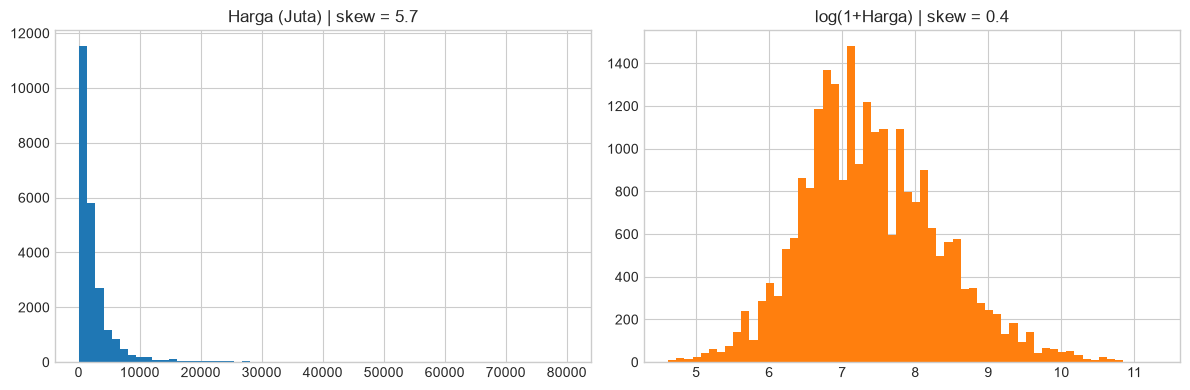

In [9]:
eda = (df_p.filter(pl.col('harga_juta').is_between(100, 100_000) & pl.col('luas_bangunan').is_between(10, 3000)
                   & (pl.col('luas_tanah').is_null() | pl.col('luas_tanah').is_between(10, 5000))
                   & pl.col('ket').is_in(['-', 'Total']) & pl.col('kamar_tidur').is_between(1, 15))
         .unique(subset=KUNCI_DUP, keep='first', maintain_order=True)
         .with_columns(pl.col('garasi').fill_null(0)))
print('Baris untuk visualisasi:', eda.height)

h = eda['harga_juta'].to_numpy()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(h, bins=60); ax[0].set_title(f'Harga (Juta) | skew = {skew(h):.1f}')
ax[1].hist(np.log1p(h), bins=60, color='C1'); ax[1].set_title(f'log(1+Harga) | skew = {skew(np.log1p(h)):.1f}')
plt.tight_layout(); plt.show()

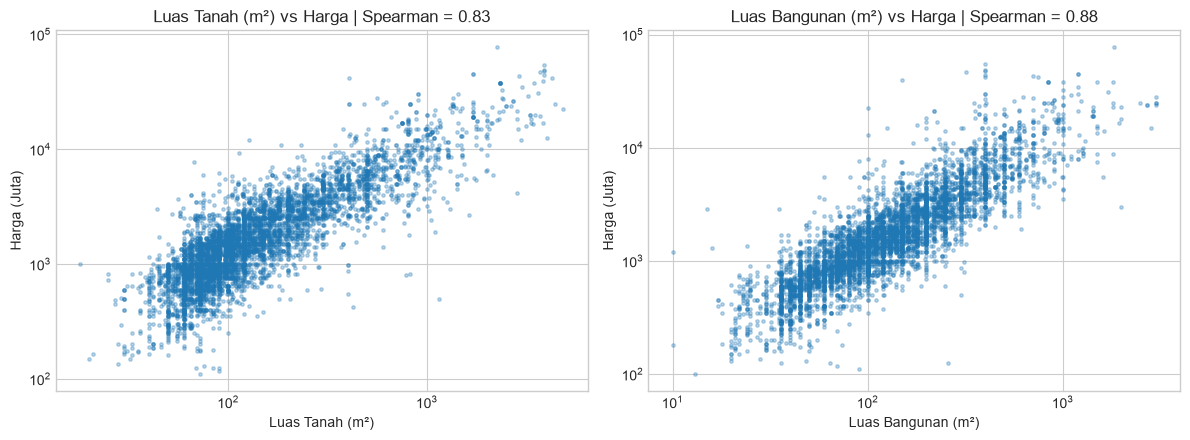

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
s = eda.sample(min(6000, eda.height), seed=SEED)
for a, kol, nama in zip(ax, ['luas_tanah', 'luas_bangunan'], ['Luas Tanah (m²)', 'Luas Bangunan (m²)']):
    a.scatter(s[kol].to_numpy(), s['harga_juta'].to_numpy(), s=6, alpha=.3)
    a.set_xscale('log'); a.set_yscale('log'); a.set_xlabel(nama); a.set_ylabel('Harga (Juta)')
    a.set_title(f"{nama} vs Harga | Spearman = {spearman(eda[kol].to_numpy(), eda['harga_juta'].to_numpy()):.2f}")
plt.tight_layout(); plt.show()

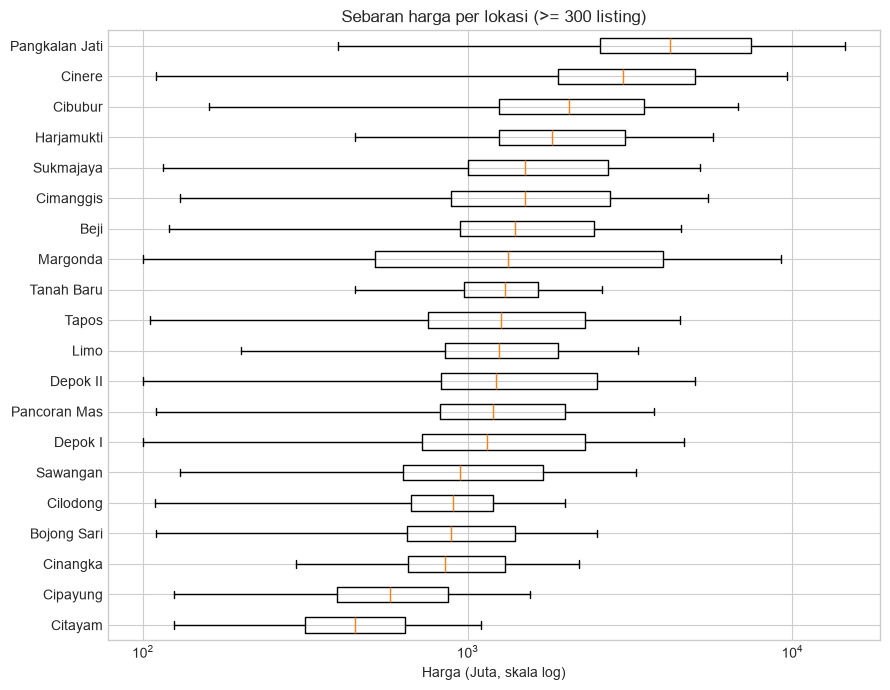

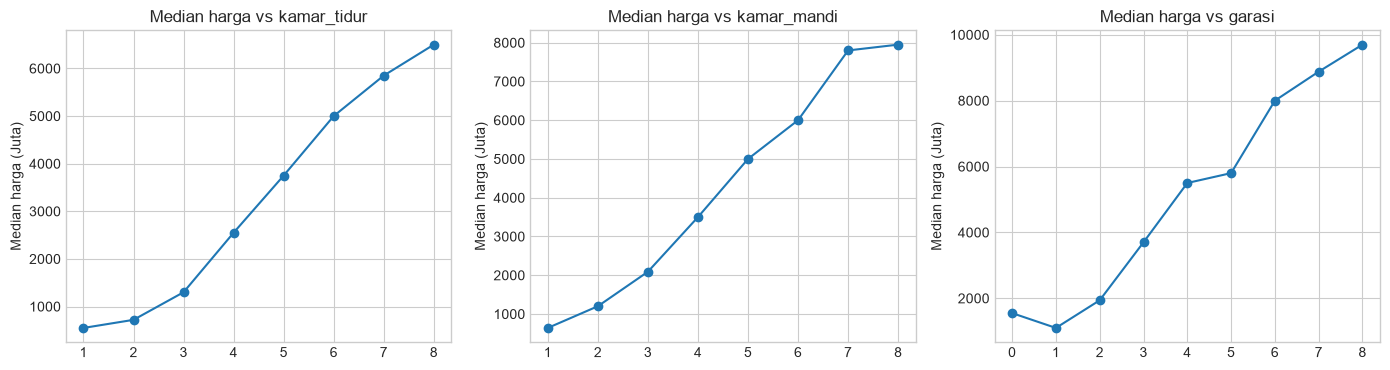

In [11]:
top = eda['kecamatan'].value_counts().filter(pl.col('count') >= 300)['kecamatan'].to_list()
urut = (eda.filter(pl.col('kecamatan').is_in(top)).group_by('kecamatan').agg(pl.col('harga_juta').median())
           .sort('harga_juta')['kecamatan'].to_list())            # termurah di bawah, termahal di atas
fig, ax = plt.subplots(figsize=(9, 7))
ax.boxplot([eda.filter(pl.col('kecamatan') == k)['harga_juta'].to_numpy() for k in urut], vert=False, showfliers=False)
ax.set_yticklabels(urut); ax.set_xscale('log'); ax.set_xlabel('Harga (Juta, skala log)')
ax.set_title('Sebaran harga per lokasi (>= 300 listing)'); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, kol in zip(ax, ['kamar_tidur', 'kamar_mandi', 'garasi']):
    m = eda.filter(pl.col(kol).is_between(0, 8)).group_by(kol).agg(pl.col('harga_juta').median()).sort(kol)
    a.plot(m[kol].to_numpy(), m['harga_juta'].to_numpy(), marker='o'); a.set_title(f'Median harga vs {kol}'); a.set_ylabel('Median harga (Juta)')
plt.tight_layout(); plt.show()

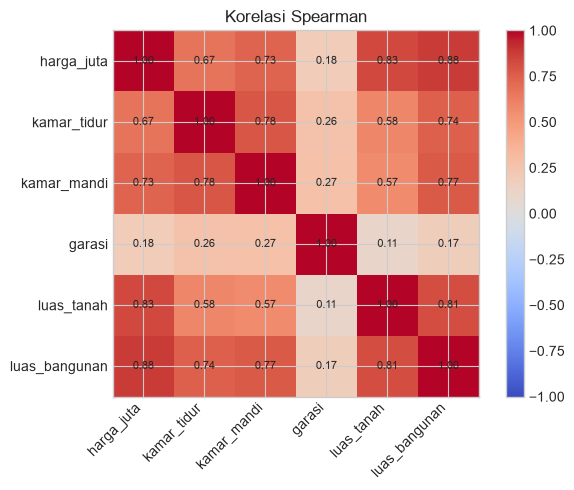

In [12]:
kol_corr = ['harga_juta', 'kamar_tidur', 'kamar_mandi', 'garasi', 'luas_tanah', 'luas_bangunan']
R = np.array([[spearman(eda[a].to_numpy(), eda[b].to_numpy()) for b in kol_corr] for a in kol_corr])
fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(R, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(kol_corr))); ax.set_xticklabels(kol_corr, rotation=45, ha='right'); ax.set_yticks(range(len(kol_corr))); ax.set_yticklabels(kol_corr)
for i in range(len(kol_corr)):
    for j in range(len(kol_corr)): ax.text(j, i, f'{R[i, j]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(im); ax.set_title('Korelasi Spearman'); plt.tight_layout(); plt.show()

In [13]:
# Angka pendukung insight
print(f'Harga: mean = {h.mean():,.0f} | median = {np.median(h):,.0f} | skew = {skew(h):.2f} -> log: {skew(np.log1p(h)):.2f}')
print('\nSpearman terhadap harga:'); print({k: round(float(v), 3) for k, v in zip(kol_corr[1:], R[0, 1:])})
med = eda.filter(pl.col('kecamatan').is_in(top)).group_by('kecamatan').agg(pl.col('harga_juta').median()).sort('harga_juta')
print('\nMedian harga per lokasi (>=300 listing): termurah', med['kecamatan'][0], f"{med['harga_juta'][0]:,.0f}", '| termahal', med['kecamatan'][-1], f"{med['harga_juta'][-1]:,.0f}", f"| rasio {med['harga_juta'][-1] / med['harga_juta'][0]:.1f}x")
n_kec = df_p['kecamatan'].value_counts()
print('Share listing Cinere:', f"{(df_p['kecamatan'] == 'Cinere').mean():.1%}", '| lokasi < 50 baris:', int((n_kec['count'] < 50).sum()), 'dari', n_kec.height)
print('Median harga per m² bangunan (Juta):', round((eda['harga_juta'] / eda['luas_bangunan']).median(), 1))
mkt = eda.filter(pl.col('kamar_tidur').is_between(1, 8)).group_by('kamar_tidur').agg(pl.col('harga_juta').median()).sort('kamar_tidur')
print('\nMedian harga per jumlah kamar tidur (Juta):', dict(zip(mkt['kamar_tidur'].to_list(), mkt['harga_juta'].round(0).to_list())))
ppm = (eda.filter(pl.col('kecamatan').is_in(top)).with_columns((pl.col('harga_juta') / pl.col('luas_bangunan')).alias('ppm'))
          .group_by('kecamatan').agg(pl.col('ppm').median()).sort('ppm'))
print('Median harga per m² bangunan antar lokasi (Juta):', f"{ppm['ppm'][0]:.1f} ({ppm['kecamatan'][0]}) s.d. {ppm['ppm'][-1]:.1f} ({ppm['kecamatan'][-1]})")
print('Duplikat setelah parsing:', f'{n_dup(df_p, KUNCI_DUP) / df_p.height:.1%}')

Harga: mean = 2,673 | median = 1,500 | skew = 5.72 -> log: 0.40

Spearman terhadap harga:
{'kamar_tidur': 0.667, 'kamar_mandi': 0.727, 'garasi': 0.181, 'luas_tanah': 0.832, 'luas_bangunan': 0.881}

Median harga per lokasi (>=300 listing): termurah Citayam 450 | termahal Pangkalan Jati 4,200 | rasio 9.3x
Share listing Cinere: 21.4% | lokasi < 50 baris: 5 dari 38
Median harga per m² bangunan (Juta): 13.1

Median harga per jumlah kamar tidur (Juta): {1.0: 550.0, 2.0: 720.0, 3.0: 1300.0, 4.0: 2550.0, 5.0: 3750.0, 6.0: 5000.0, 7.0: 5850.0, 8.0: 6500.0}
Median harga per m² bangunan antar lokasi (Juta): 8.7 (Citayam) s.d. 19.9 (Pangkalan Jati)
Duplikat setelah parsing: 30.7%


### 1.7 Insight utama
**Insight 1 – Harga sangat miring ke kanan.** Rata-rata (≈2.673 Jt) jauh di atas median (1.500 Jt), skewness 5,7 dan turun menjadi 0,4 setelah di-log.
→ Keputusan: target dilatih dalam `log1p` (`TransformedTargetRegressor`), lalu dikembalikan ke Juta saat evaluasi; MAPE dipakai di samping MAE karena error absolut didominasi rumah mahal.

**Insight 2 – Ukuran fisik adalah penentu harga utama, tetapi hubungannya tidak linear.** Spearman terhadap harga: Luas Bangunan 0,88, Luas Tanah 0,83, Kamar Mandi 0,73, Kamar Tidur 0,67, Garasi hanya 0,18. Median harga naik dari ±550 Jt (1 kamar tidur) menjadi ±6.500 Jt (8 kamar tidur), yaitu naik berlipat, bukan konstan.
→ Keputusan: tambah fitur turunan (`log_luas_*`, `total_kamar`, `rasio_lb_lt`) agar model linear menangkap skala; uji model berbasis pohon/ensemble yang menangkap non-linearitas; `Garasi` lemah dan sering kosong sehingga diisi 0 dan diuji lewat feature selection.

**Insight 3 – Lokasi berpengaruh, tetapi sebagian besar selisihnya berasal dari ukuran rumah, dan datanya timpang.** Median harga antar lokasi (≥300 listing) berkisar dari ±450 Jt (Citayam) hingga ±4.200 Jt (Pangkalan Jati), selisih 9,3×. Setelah dinormalisasi per m² bangunan selisihnya menyempit (±8,7 sampai ±19,9 Jt/m²), dengan Pangkalan Jati, Margonda, dan Cinere sebagai area premium. Cinere memuat 21,4% data sedangkan 5 dari 38 label lokasi punya < 50 baris, dan label bercampur level (kecamatan, kelurahan, kawasan).
→ Keputusan: one-hot `Kecamatan` dengan `min_frequency=50` (lokasi jarang digabung), flag `kecamatan_resmi`, dan model pohon untuk menangkap interaksi lokasi × luas.

**Insight 4 – Nilai ekstrem harus dibedakan dari salah input lewat konsistensi harga per m², bukan besar harganya.** Harga mentah mencapai miliaran Juta (satuan `Triliun`), sementara rumah mewah ratusan miliar masih mungkin valid. Median harga per m² bangunan ±13 Jt, sehingga listing dengan harga/m² di luar rentang wajar (3×IQR skala log) atau luas yang mustahil adalah salah input.
→ Keputusan: buang satuan `Ribu`/`Triliun`, batasi harga Rp100 jt–Rp100 M, buang harga/m² yang tidak konsisten, dan **buang duplikat sebelum split** (±31% baris adalah duplikat) agar baris kembar tidak masuk train dan test sekaligus.

## 2. Direct Modeling (kontrol, sebelum preprocessing)

Hanya konversi minimal agar teks menjadi angka: harga dikonversi dengan satuan Juta/Miliar, kolom lain diambil **angka pertamanya apa adanya**
(tanpa realign, tanpa buang duplikat/outlier, kolom `Page` ikut). Missing diisi median, `Kecamatan` di-one-hot. Target tanpa transformasi.

**Alasan pemilihan model:**
- **Linear Regression**: baseline paling sederhana, melihat seberapa jauh hubungan linear bisa menjelaskan harga.
- **Ridge**: fitur luas tanah/bangunan/kamar saling berkorelasi, regularisasi L2 menstabilkan koefisien.
- **Decision Tree**: menangkap hubungan non-linear dan interaksi lokasi × luas tanpa asumsi distribusi.
- **Random Forest** (ensemble bagging): meredam variansi pohon tunggal dan cukup tahan terhadap outlier.
- **HistGradientBoosting** (ensemble boosting): kuat untuk data tabular ~40 ribu baris, menangani missing value secara native.
- **XGBoost** (ensemble boosting): boosting dengan regularisasi, umumnya yang terbaik untuk data tabular berskala menengah.

In [14]:
def evaluasi(y_true, y_pred):
    return {'MAE': float(mean_absolute_error(y_true, y_pred)),
            'MAPE': float(mean_absolute_percentage_error(y_true, y_pred) * 100),
            'R2': float(r2_score(y_true, y_pred)),
            'RMSE': float(np.sqrt(mean_squared_error(y_true, y_pred)))}

def daftar_model():
    return {
        'Linear Regression': LinearRegression(),
        'Ridge': Ridge(alpha=1.0),
        'Decision Tree': DecisionTreeRegressor(random_state=SEED),
        'Random Forest': RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=SEED),
        'HistGradientBoosting': HistGradientBoostingRegressor(random_state=SEED),
        'XGBoost': XGBRegressor(n_estimators=300, learning_rate=0.1, tree_method='hist', n_jobs=-1, random_state=SEED),
    }

hasil = []   # kumpulan hasil semua tahap
tabel = lambda tahap: bulat(pl.DataFrame([h for h in hasil if h['Tahap'] == tahap]))

In [15]:
num0 = KOLOM_FITUR + ['Page']
d0 = (df_raw.with_columns(parse_harga(df_raw)['harga_juta'])
            .drop_nulls('harga_juta')                                                  # target tidak boleh kosong
            .with_columns([pl.col(c).str.extract(r'(\d+)').cast(pl.Float64) for c in KOLOM_FITUR]))  # angka pertama apa adanya

X0, y0 = d0.select(num0 + ['Kecamatan']).to_numpy(), d0['harga_juta'].to_numpy()      # 6 kolom numerik + Kecamatan
X0_tr, X0_te, y0_tr, y0_te = train_test_split(X0, y0, test_size=0.2, random_state=SEED)

prep0 = ColumnTransformer([('num', SimpleImputer(strategy='median'), list(range(len(num0)))),
                           ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), [len(num0)])])
for nama, m in daftar_model().items():
    t = time.time()
    pipe = Pipeline([('prep', clone(prep0)), ('model', m)]).fit(X0_tr, y0_tr)
    hasil.append({'Tahap': '1. Direct', 'Model': nama, **evaluasi(y0_te, pipe.predict(X0_te))})
    print(f'{nama:22s} {time.time()-t:5.1f}s')
tabel('1. Direct')

Linear Regression        0.4s
Ridge                    0.2s
Decision Tree            1.2s
Random Forest           13.3s
HistGradientBoosting     0.3s
XGBoost                  1.7s


Tahap,Model,MAE,MAPE,R2,RMSE
str,str,f64,f64,f64,f64
"""1. Direct""","""Linear Regression""",1.3965e6,127357.15,-228.26,1.0463e8
"""1. Direct""","""Ridge""",1.3961e6,127347.75,-228.23,1.0463e8
"""1. Direct""","""Decision Tree""",548349.4,5519.83,-17.99,3.0111e7
"""1. Direct""","""Random Forest""",320916.97,23653.02,-0.6,8.7328e6
"""1. Direct""","""HistGradientBoosting""",299607.1,155674.32,-0.03,7013396.8
"""1. Direct""","""XGBoost""",402386.19,373413.22,-9.13,2.1993e7


Hasil ini jadi **kontrol**. Catatan: test set tahap ini masih berisi outlier, sehingga angka R²/MAPE-nya tidak sepenuhnya sebanding dengan tahap berikutnya (test set bersih).

## 3. Modeling dengan Preprocessing

Langkah pembersihan (urut):
1. Parsing harga (satuan, `Total`, `/m²`), buang harga tanpa angka / satuan tidak wajar.
2. Realign kolom berdasarkan token (`LT`/`LB`/angka).
3. Buang listing non-hunian (tanpa Kamar Tidur / Luas Bangunan), `Garasi` kosong diisi 0.
4. Buang duplikat berdasarkan fitur listing (abaikan Page & Kecamatan).
5. Buang outlier tidak wajar: batas domain + konsistensi harga per m² bangunan (3×IQR skala log).
6. Buang `Page`; tambah fitur baru; target di-log (`log1p`) saat training.

Fitur turunan ditulis di `fitur.py` (Polars) agar bisa dipakai ulang di Streamlit.

In [16]:
%%writefile fitur.py
import polars as pl

KECAMATAN_RESMI = ['Beji', 'Bojong Sari', 'Cilodong', 'Cimanggis', 'Cinere', 'Cipayung',
                   'Limo', 'Pancoran Mas', 'Sawangan', 'Sukmajaya', 'Tapos']

NUM = ['kamar_tidur', 'kamar_mandi', 'garasi', 'luas_tanah', 'luas_bangunan', 'total_kamar', 'ada_garasi',
       'rasio_lb_lt', 'log_luas_tanah', 'log_luas_bangunan', 'kecamatan_resmi']


def add_features(df: pl.DataFrame) -> pl.DataFrame:
    return df.with_columns(
        (pl.col('kamar_tidur') + pl.col('kamar_mandi')).alias('total_kamar'),
        (pl.col('garasi') > 0).cast(pl.Int64).alias('ada_garasi'),
        pl.when(pl.col('luas_tanah') > 0).then(pl.col('luas_bangunan') / pl.col('luas_tanah')).alias('rasio_lb_lt'),
        pl.col('luas_tanah').log1p().alias('log_luas_tanah'),
        pl.col('luas_bangunan').log1p().alias('log_luas_bangunan'),
        pl.col('kecamatan').is_in(KECAMATAN_RESMI).cast(pl.Int64).alias('kecamatan_resmi'),
    )


def ke_matriks(df: pl.DataFrame):
    """6 kolom bersih (polars) -> matriks fitur [NUM..., kecamatan] untuk scikit-learn."""
    return add_features(df).select(NUM + ['kecamatan']).to_numpy()

Overwriting fitur.py


In [17]:
from fitur import add_features, ke_matriks, NUM

def bersihkan(df_p):
    d, log = df_p, []
    catat = lambda langkah: log.append((langkah, d.height))
    catat('Data awal')
    d = d.filter(pl.col('satuan') != 'Tanpa angka');                                              catat('Buang harga tanpa angka (Hubungi Agen)')
    d = d.filter(~pl.col('satuan').is_in(['Ribu', 'Triliun']) & (pl.col('ket') != '/ha'));        catat('Buang satuan harga tidak wajar (Ribu / Triliun / per ha)')
    d = (d.with_columns(pl.when(pl.col('ket') == '/m²').then(pl.col('harga_juta') * pl.col('luas_tanah'))
                          .otherwise(pl.col('harga_juta')).alias('harga_juta'))
          .drop_nulls('harga_juta'));                                                              catat('Harga per m² x Luas Tanah (buang jika LT kosong)')
    d = d.drop_nulls(['kamar_tidur', 'luas_bangunan']);                                            catat('Buang listing non-hunian (tanpa KT / LB)')
    d = d.with_columns(pl.col('garasi').fill_null(0))
    d = d.unique(subset=KUNCI_DUP, keep='first', maintain_order=True);                            catat('Buang duplikat (abaikan Page & Kecamatan)')

    aturan = {
        'Harga di luar Rp100 jt - Rp100 M': ~pl.col('harga_juta').is_between(100, 100_000),
        'Luas bangunan di luar 10-3.000 m²': ~pl.col('luas_bangunan').is_between(10, 3000),
        'Luas tanah di luar 10-5.000 m²': pl.col('luas_tanah').is_not_null() & ~pl.col('luas_tanah').is_between(10, 5000),
        'Kamar tidur/mandi > 15 atau garasi > 10': (pl.col('kamar_tidur') > 15) | (pl.col('kamar_mandi') > 15) | (pl.col('garasi') > 10),
        'Luas bangunan > 6x luas tanah': pl.col('luas_bangunan') > 6 * pl.col('luas_tanah'),
    }
    aturan = {k: v.fill_null(False) for k, v in aturan.items()}
    lp = (pl.col('harga_juta') / pl.col('luas_bangunan')).log()
    lp_ok = d.filter(~pl.any_horizontal(list(aturan.values()))).select(lp.alias('lp'))['lp']
    q1, q3 = lp_ok.quantile(0.25, 'linear'), lp_ok.quantile(0.75, 'linear'); iqr = q3 - q1
    aturan[f'Harga/m² bangunan di luar {np.exp(q1-3*iqr):.1f} - {np.exp(q3+3*iqr):.1f} Jt (3xIQR log)'] = ((lp < q1 - 3*iqr) | (lp > q3 + 3*iqr)).fill_null(False)
    ringkas = pl.DataFrame({'aturan': list(aturan), 'baris terdeteksi': [d.filter(v).height for v in aturan.values()]})
    d = d.filter(~pl.any_horizontal(list(aturan.values())));                                       catat('Buang outlier tidak wajar')
    return d, pl.DataFrame(log, schema=['Langkah', 'Sisa baris'], orient='row'), ringkas

df_clean, audit, ringkas_outlier = bersihkan(df_p)
display(audit); display(ringkas_outlier)

Langkah,Sisa baris
str,i64
"""Data awal""",40200
"""Buang harga tanpa angka (Hubungi Agen)""",40159
"""Buang satuan harga tidak wajar (Ribu / Triliun / per ha)""",40079
"""Harga per m² x Luas Tanah (buang jika LT kosong)""",40077
"""Buang listing non-hunian (tanpa KT / LB)""",35208
"""Buang duplikat (abaikan Page & Kecamatan)""",24483
"""Buang outlier tidak wajar""",23673


aturan,baris terdeteksi
str,i64
"""Harga di luar Rp100 jt - Rp100 M""",282
"""Luas bangunan di luar 10-3.000 m²""",65
"""Luas tanah di luar 10-5.000 m²""",67
"""Kamar tidur/mandi > 15 atau garasi > 10""",359
"""Luas bangunan > 6x luas tanah""",32
"""Harga/m² bangunan di luar 2.1 - 81.8 Jt (3xIQR log)""",398


In [18]:
FITUR_BASE = ['kamar_tidur', 'kamar_mandi', 'garasi', 'luas_tanah', 'luas_bangunan', 'kecamatan']
X, y = df_clean.select(FITUR_BASE), df_clean['harga_juta'].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print(f"Harga bersih: median = {np.median(y):,.0f} Jt | skew = {skew(y):.2f} -> log: {skew(np.log1p(y)):.2f}")

# input scikit-learn = matriks hasil ke_matriks: kolom 0..10 numerik (NUM), kolom 11 = kecamatan
prep = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), list(range(len(NUM)))),
    ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=50, sparse_output=False), [len(NUM)]),
])

def log_target(model):
    return TransformedTargetRegressor(regressor=model, func=np.log1p, inverse_func=np.expm1)

for nama, m in daftar_model().items():
    t = time.time()
    pipe = Pipeline([('fe', FunctionTransformer(ke_matriks)), ('prep', clone(prep)), ('model', log_target(m))]).fit(X_train, y_train)
    hasil.append({'Tahap': '2. Preprocessing', 'Model': nama, **evaluasi(y_test, pipe.predict(X_test))})
    print(f'{nama:22s} {time.time()-t:5.1f}s')
tabel('2. Preprocessing')

Train: (18938, 6) | Test: (4735, 6)
Harga bersih: median = 1,500 Jt | skew = 5.64 -> log: 0.38
Linear Regression        0.2s
Ridge                    0.3s
Decision Tree            0.5s
Random Forest            5.0s
HistGradientBoosting     1.5s
XGBoost                  1.8s


Tahap,Model,MAE,MAPE,R2,RMSE
str,str,f64,f64,f64,f64
"""2. Preprocessing""","""Linear Regression""",753.42,28.24,0.72,1919.97
"""2. Preprocessing""","""Ridge""",753.45,28.25,0.72,1919.91
"""2. Preprocessing""","""Decision Tree""",719.94,29.23,0.7,2002.5
"""2. Preprocessing""","""Random Forest""",573.06,22.84,0.83,1490.12
"""2. Preprocessing""","""HistGradientBoosting""",657.77,24.88,0.8,1624.76
"""2. Preprocessing""","""XGBoost""",625.08,23.87,0.82,1536.58


## 4. Feature Selection

Metode: **korelasi Spearman** (hubungan monotonik dengan target) dan **Mutual Information** (hubungan non-linear), dihitung pada data latih.
Fitur dipertahankan jika Mutual Information ≥ 0,02; sisanya (mis. kategori lokasi yang jarang) dibuang.

In [19]:
fe = FunctionTransformer(ke_matriks).fit(X_train)
Xm_tr, Xm_te = fe.transform(X_train), fe.transform(X_test)
prep_fs = clone(prep).fit(Xm_tr)
Xtr_t, Xte_t = prep_fs.transform(Xm_tr), prep_fs.transform(Xm_te)
nama_fitur = NUM + list(prep_fs.named_transformers_['cat'].get_feature_names_out(['kecamatan']))
y_train_log = np.log1p(y_train)

selector = SelectKBest(partial(mutual_info_regression, random_state=SEED), k='all').fit(Xtr_t, y_train_log)
skor = (pl.DataFrame({'fitur': nama_fitur, 'MI': selector.scores_,
                      'spearman': [spearman(Xtr_t[:, i], y_train) for i in range(Xtr_t.shape[1])]})
          .fill_nan(0).sort('MI', descending=True))
display(bulat(skor, 3).head(25))

fitur,MI,spearman
str,f64,f64
"""log_luas_bangunan""",0.933,0.885
"""luas_bangunan""",0.927,0.885
"""log_luas_tanah""",0.879,0.802
"""luas_tanah""",0.874,0.802
"""total_kamar""",0.43,0.721
"""kamar_mandi""",0.376,0.689
"""rasio_lb_lt""",0.345,0.073
"""kamar_tidur""",0.345,0.668
"""garasi""",0.137,0.182


13 dari 42 fitur dipilih:
['kamar_tidur', 'kamar_mandi', 'garasi', 'luas_tanah', 'luas_bangunan', 'total_kamar', 'rasio_lb_lt', 'log_luas_tanah', 'log_luas_bangunan', 'kecamatan_Cilodong', 'kecamatan_Cinere', 'kecamatan_Citayam', 'kecamatan_Sawangan']
Dibuang: ['ada_garasi', 'kecamatan_resmi', 'kecamatan_Beji', 'kecamatan_Bojong Sari', 'kecamatan_Cibubur', 'kecamatan_Cilangkap', 'kecamatan_Cimanggis', 'kecamatan_Cinangka', 'kecamatan_Cipayung', 'kecamatan_Cisalak', 'kecamatan_Depok I', 'kecamatan_Depok II', 'kecamatan_Gandul', 'kecamatan_Harjamukti', 'kecamatan_Kelapa Dua', 'kecamatan_Krukut', 'kecamatan_Kukusan', 'kecamatan_Limo', 'kecamatan_Margonda', 'kecamatan_Mekarsari', 'kecamatan_Pancoran Mas', 'kecamatan_Pangkalan Jati', 'kecamatan_Pasir Putih', 'kecamatan_Rangkapanjaya', 'kecamatan_Sukatani', 'kecamatan_Sukmajaya', 'kecamatan_Tanah Baru', 'kecamatan_Tapos', 'kecamatan_infrequent_sklearn']


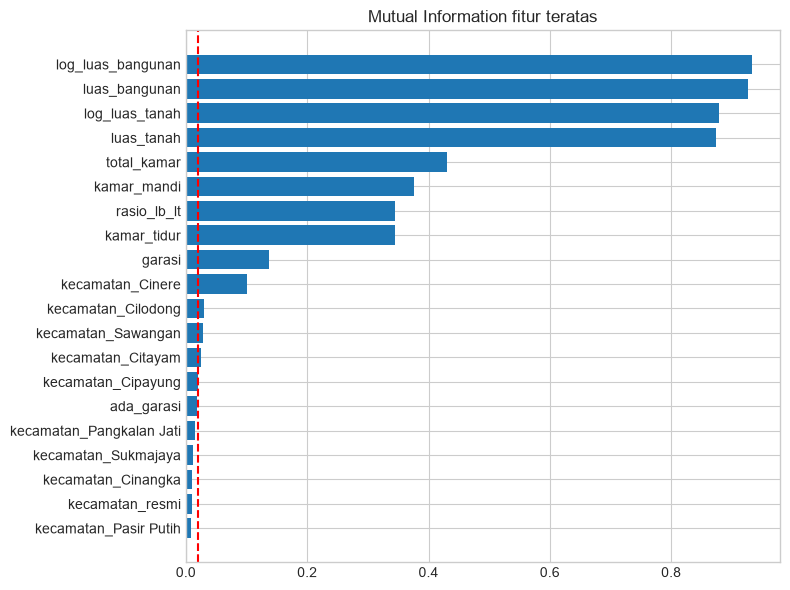

In [20]:
AMBANG_MI = 0.02
k = int((skor['MI'] >= AMBANG_MI).sum())
selector.set_params(k=k)            # skor MI sudah dihitung; hanya jumlah fitur yang dipilih diubah
dipilih = [n for n, s in zip(nama_fitur, selector.get_support()) if s]
print(f'{k} dari {len(nama_fitur)} fitur dipilih:'); print(dipilih)
print('Dibuang:', [n for n in nama_fitur if n not in dipilih])

top20 = skor.head(20)
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top20['fitur'].to_list()[::-1], top20['MI'].to_numpy()[::-1]); ax.axvline(AMBANG_MI, color='r', ls='--')
ax.set_title('Mutual Information fitur teratas'); plt.tight_layout(); plt.show()

In [21]:
Xtr_s, Xte_s = selector.transform(Xtr_t), selector.transform(Xte_t)
for nama, m in daftar_model().items():
    t = time.time()
    reg = log_target(m).fit(Xtr_s, y_train)
    hasil.append({'Tahap': '3. Feature Selection', 'Model': nama, **evaluasi(y_test, reg.predict(Xte_s))})
    print(f'{nama:22s} {time.time()-t:5.1f}s')
tabel('3. Feature Selection')

Linear Regression        0.0s
Ridge                    0.0s
Decision Tree            0.2s
Random Forest            2.1s
HistGradientBoosting     0.5s
XGBoost                  0.6s


Tahap,Model,MAE,MAPE,R2,RMSE
str,str,f64,f64,f64,f64
"""3. Feature Selection""","""Linear Regression""",777.63,29.49,0.72,1947.9
"""3. Feature Selection""","""Ridge""",777.6,29.49,0.72,1947.8
"""3. Feature Selection""","""Decision Tree""",770.25,30.92,0.61,2273.98
"""3. Feature Selection""","""Random Forest""",610.35,24.25,0.81,1596.75
"""3. Feature Selection""","""HistGradientBoosting""",690.07,25.99,0.77,1740.92
"""3. Feature Selection""","""XGBoost""",649.14,24.84,0.8,1626.79


## 5. Hyperparameter Tuning

`RandomizedSearchCV` (3-fold CV, metrik MAE) **hanya pada data latih** dengan fitur hasil seleksi. Linear Regression tidak punya hyperparameter utama sehingga tidak dituning.

In [22]:
ruang = {
    'Ridge': (Ridge(), {'regressor__alpha': [0.01, 0.1, 1, 10, 100]}, 5),
    'Decision Tree': (DecisionTreeRegressor(random_state=SEED),
                      {'regressor__max_depth': [6, 8, 10, 12, 16], 'regressor__min_samples_leaf': [3, 5, 10, 20]}, 8),
    'Random Forest': (RandomForestRegressor(random_state=SEED, n_jobs=-1),
                      {'regressor__n_estimators': [100, 150], 'regressor__max_depth': [12, 16, 20],
                       'regressor__min_samples_leaf': [1, 2, 5], 'regressor__max_features': [0.5, 0.8, 1.0]}, 5),
    'HistGradientBoosting': (HistGradientBoostingRegressor(random_state=SEED),
                      {'regressor__learning_rate': [0.03, 0.05, 0.1], 'regressor__max_iter': [200, 400],
                       'regressor__max_leaf_nodes': [15, 31, 63], 'regressor__min_samples_leaf': [20, 50],
                       'regressor__l2_regularization': [0, 1]}, 8),
    'XGBoost': (XGBRegressor(tree_method='hist', n_jobs=-1, random_state=SEED),
                {'regressor__n_estimators': [200, 400], 'regressor__max_depth': [4, 6, 8],
                 'regressor__learning_rate': [0.03, 0.05, 0.1], 'regressor__subsample': [0.7, 0.9, 1.0],
                 'regressor__colsample_bytree': [0.7, 0.9, 1.0]}, 8),
}
tuned, param_terbaik = {}, []
for nama, (m, grid, n_iter) in ruang.items():
    t = time.time()
    cari = RandomizedSearchCV(log_target(m), grid, n_iter=n_iter, cv=3, scoring='neg_mean_absolute_error',
                              random_state=SEED, n_jobs=-1).fit(Xtr_s, y_train)
    tuned[nama] = cari
    hasil.append({'Tahap': '4. Tuning', 'Model': nama, **evaluasi(y_test, cari.predict(Xte_s))})
    param_terbaik.append({'Model': nama, 'CV MAE (Jt)': float(-cari.best_score_),
                          'Best params': str({k.replace('regressor__', ''): v for k, v in cari.best_params_.items()})})
    print(f'{nama:22s} {time.time()-t:6.1f}s')
bulat(pl.DataFrame(param_terbaik), 1)

Ridge                     4.8s
Decision Tree             0.6s
Random Forest            20.2s
HistGradientBoosting     10.5s
XGBoost                   7.3s


Model,CV MAE (Jt),Best params
str,f64,str
"""Ridge""",791.4,"""{'alpha': 100}"""
"""Decision Tree""",745.1,"""{'min_samples_leaf': 20, 'max_depth': 10}"""
"""Random Forest""",630.0,"""{'n_estimators': 150, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 16}"""
"""HistGradientBoosting""",692.2,"""{'min_samples_leaf': 20, 'max_leaf_nodes': 63, 'max_iter': 200, 'learning_rate': 0.1, 'l2_…"
"""XGBoost""",666.0,"""{'subsample': 1.0, 'n_estimators': 200, 'max_depth': 8, 'learning_rate': 0.1, 'colsample_b…"


## 6. Perbandingan Hasil & Model Terbaik

In [23]:
df_hasil = pl.DataFrame(hasil)
tahap = ['1. Direct', '2. Preprocessing', '3. Feature Selection', '4. Tuning']
for met in ['MAE', 'MAPE', 'R2']:
    print(f'--- {met} ---')
    display(bulat(df_hasil.pivot(on='Tahap', index='Model', values=met).select(['Model'] + tahap)))

--- MAE ---


Model,1. Direct,2. Preprocessing,3. Feature Selection,4. Tuning
str,f64,f64,f64,f64
"""Linear Regression""",1.3965e6,753.42,777.63,null
"""Ridge""",1.3961e6,753.45,777.6,775.7
"""Decision Tree""",548349.4,719.94,770.25,730.3
"""Random Forest""",320916.97,573.06,610.35,609.07
"""HistGradientBoosting""",299607.1,657.77,690.07,662.31
"""XGBoost""",402386.19,625.08,649.14,624.65


--- MAPE ---


Model,1. Direct,2. Preprocessing,3. Feature Selection,4. Tuning
str,f64,f64,f64,f64
"""Linear Regression""",127357.15,28.24,29.49,null
"""Ridge""",127347.75,28.25,29.49,29.54
"""Decision Tree""",5519.83,29.23,30.92,27.71
"""Random Forest""",23653.02,22.84,24.25,23.9
"""HistGradientBoosting""",155674.32,24.88,25.99,24.99
"""XGBoost""",373413.22,23.87,24.84,24.18


--- R2 ---


Model,1. Direct,2. Preprocessing,3. Feature Selection,4. Tuning
str,f64,f64,f64,f64
"""Linear Regression""",-228.26,0.72,0.72,null
"""Ridge""",-228.23,0.72,0.72,0.72
"""Decision Tree""",-17.99,0.7,0.61,0.75
"""Random Forest""",-0.6,0.83,0.81,0.81
"""HistGradientBoosting""",-0.03,0.8,0.77,0.79
"""XGBoost""",-9.13,0.82,0.8,0.81


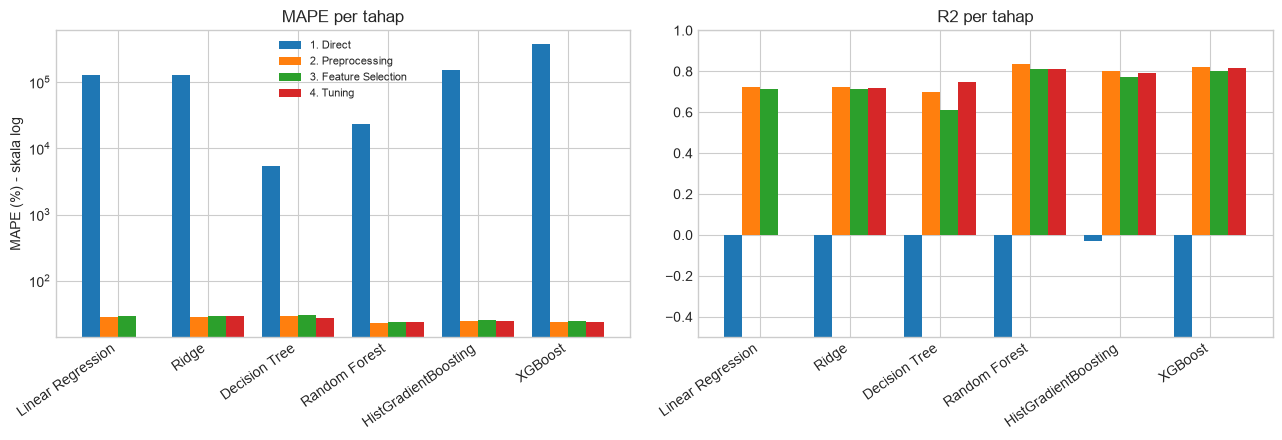

In [24]:
model_urut = df_hasil['Model'].unique(maintain_order=True).to_list()
def bar_grup(ax, met):
    w = 0.2
    for j, t in enumerate(tahap):
        nilai = [next(iter(df_hasil.filter((pl.col('Model') == m) & (pl.col('Tahap') == t))[met].to_list()), np.nan) for m in model_urut]
        ax.bar(np.arange(len(model_urut)) + j * w, nilai, w, label=t)
    ax.set_xticks(np.arange(len(model_urut)) + 1.5 * w); ax.set_xticklabels(model_urut, rotation=35, ha='right'); ax.set_title(met + ' per tahap')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
bar_grup(ax[0], 'MAPE'); ax[0].set_yscale('log'); ax[0].set_ylabel('MAPE (%) - skala log'); ax[0].legend(fontsize=8)
bar_grup(ax[1], 'R2'); ax[1].set_ylim(-0.5, 1)
plt.tight_layout(); plt.show()

Model terbaik dipilih dari hasil tuning pada **test set bersih** dengan rata-rata peringkat MAE, MAPE, dan R².

Tahap,Model,MAE,MAPE,R2,RMSE,rank
str,str,f64,f64,f64,f64,f64
"""4. Tuning""","""Random Forest""",609.075,23.897,0.811,1589.557,4.0
"""4. Tuning""","""XGBoost""",624.65,24.179,0.814,1575.649,5.0
"""4. Tuning""","""HistGradientBoosting""",662.31,24.99,0.792,1665.881,9.0
"""4. Tuning""","""Decision Tree""",730.295,27.712,0.749,1830.212,12.0
"""4. Tuning""","""Ridge""",775.703,29.545,0.719,1939.338,15.0


Model terbaik: Random Forest


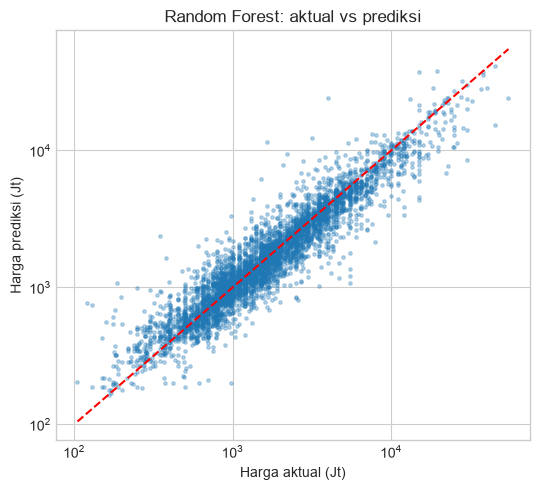

In [25]:
tt = (df_hasil.filter(pl.col('Tahap') == '4. Tuning')
        .with_columns((pl.col('MAE').rank() + pl.col('MAPE').rank() + pl.col('R2').rank(descending=True)).alias('rank'))
        .sort('rank'))
display(bulat(tt, 3))
best_name = tt['Model'][0]
best_est = tuned[best_name].best_estimator_
print('Model terbaik:', best_name)

pred = best_est.predict(Xte_s)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(y_test, pred, s=6, alpha=.3); lim = [y_test.min(), y_test.max()]; ax.plot(lim, lim, 'r--')
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('Harga aktual (Jt)'); ax.set_ylabel('Harga prediksi (Jt)')
ax.set_title(f'{best_name}: aktual vs prediksi'); plt.tight_layout(); plt.show()

## 7. Simpan Model (untuk Streamlit)

Seluruh alur (fitur turunan → preprocessing → seleksi → model) dirakit menjadi satu `Pipeline` yang menerima **DataFrame Polars** dengan 6 kolom bersih
(`kamar_tidur, kamar_mandi, garasi, luas_tanah, luas_bangunan, kecamatan`). File `fitur.py` harus ikut di-repo karena dipakai saat load model.

In [26]:
model_final = Pipeline([('fe', fe), ('prep', prep_fs), ('select', selector), ('model', best_est)])
cek = evaluasi(y_test, model_final.predict(X_test))
print('Evaluasi pipeline final (harus sama dengan hasil tuning):', {k: round(v, 3) for k, v in cek.items()})

joblib.dump(model_final, 'model_harga_rumah.joblib', compress=3)   # compress agar < 100 MB (batas GitHub)
df_clean.select(FITUR_BASE + ['harga_juta']).write_csv('data_bersih.csv')
meta = {
    'model': best_name, 'fitur_input': FITUR_BASE,
    'kecamatan': sorted(df_clean['kecamatan'].unique().to_list()),
    'rentang': {c: [float(df_clean[c].quantile(.01, 'linear')), float(df_clean[c].quantile(.99, 'linear'))]
                for c in ['kamar_tidur', 'kamar_mandi', 'garasi', 'luas_tanah', 'luas_bangunan']},
    'metrik_test': cek,
}
json.dump(meta, open('meta_model.json', 'w'), indent=2)

# uji load + prediksi satu contoh
loaded = joblib.load('model_harga_rumah.joblib')
contoh = pl.DataFrame({'kamar_tidur': [3], 'kamar_mandi': [2], 'garasi': [1], 'luas_tanah': [90], 'luas_bangunan': [70], 'kecamatan': ['Cinere']})
print(f'Contoh prediksi: Rp {loaded.predict(contoh)[0]:,.0f} juta')

Evaluasi pipeline final (harus sama dengan hasil tuning): {'MAE': 609.075, 'MAPE': 23.897, 'R2': 0.811, 'RMSE': 1589.557}
Contoh prediksi: Rp 992 juta


In [27]:
# Download file (Colab)
try:
    from google.colab import files
    for f in ['model_harga_rumah.joblib', 'fitur.py', 'data_bersih.csv', 'meta_model.json']: files.download(f)
except ImportError:
    pass

## Kesimpulan
- Direct modeling pada data mentah hasilnya buruk karena kolom bergeser, harga/luas salah input, dan duplikat; preprocessing memperbaikinya secara jelas (lihat tabel §6).
- Feature selection menyederhanakan fitur (42 → 13) dengan penurunan akurasi kecil karena sebagian dummy lokasi ikut terbuang; tuning memberi perbaikan terutama pada Decision Tree dan XGBoost.
- Model terbaik dan metrik test set tercantum di §6, dan disimpan sebagai `model_harga_rumah.joblib` untuk tahap Streamlit.